In [9]:
# ==============================================================================
# Cell 1: Imports and Setup
# ==============================================================================
import os
import math
import copy
import csv
import zipfile
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


import sys
import subprocess
import importlib
from dotenv import load_dotenv
from IPython import get_ipython


from residual_mlp_baseline.model import ResidualMLP
from residual_mlp_baseline.train import prepare, TASKS
from residual_mlp_baseline.telemetry import ResidualMLPTelemetry, compute_exact_update_ratios
from residual_mlp_baseline.ablation import run_branch_ablation

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

IMPORT_NAME = "residual_mlp_baseline"
DATA_DIR = "data"
SEED = 0

NUM_CLASSES = {"mnist": 10, "cifar10": 10, "imagenet32": 1000}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Testing", IMPORT_NAME, "on", DEVICE)

load_dotenv()
clays_laptop = os.getenv("CLAYS_LAPTOP", False).lower() in ("true", "1", "t") # read from my .env 

if not clays_laptop:
    print("HPC mode: installing packages")
    # Run pip commands directly using the active Python executable
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", 
        "--force-reinstall", "--no-deps", PACKAGE_URL
    ])
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "datasets"
    ])
    
    # Import the newly installed package
    student = importlib.import_module(IMPORT_NAME)
    print(f"Loaded installed package: {student.__name__}")

else:
    print("Local dev mode (Clay's Laptop): Loading from src/")
    
    # Configure autoreload programmatically
    ip = get_ipython()
    if ip is not None:
        ip.run_line_magic("load_ext", "autoreload")
        ip.run_line_magic("autoreload", "2")
    
    # Append local src directory to path
    if "src" not in sys.path:
        sys.path.append("src")
        
    # Import dynamically from local src directory
    student = importlib.import_module(IMPORT_NAME)
    print(f"Loaded local module: {student.__name__}")

def load_task(task):
    """Return X_train, y_train, X_test, y_test, downloading only if there is no saved copy.

    The arrays are memory-mapped: they are read from disk as they are used
    instead of all being loaded into RAM up front.
    """
    folder = os.path.join(DATA_DIR, task)
    old_file = os.path.join(DATA_DIR, f"{task}.npz")   # saved by an earlier version of this notebook

    if not os.path.isdir(folder) and os.path.exists(old_file):
        # Unpack the earlier single-file copy into the folder format; no download needed.
        print(f"{task}: unpacking {old_file} (one time only; you can delete it afterwards)")
        temp_folder = folder + ".partial"
        os.makedirs(temp_folder, exist_ok=True)
        # An .npz file is a zip of .npy files, so extracting it streams them to disk
        # without loading the arrays into memory.
        with zipfile.ZipFile(old_file) as old:
            old.extractall(temp_folder)
        os.replace(temp_folder, folder)

    if not os.path.isdir(folder):                    # no saved copy yet: download it
        from datasets import load_dataset
        name, image_column, train_split, test_split = SOURCES[task]
        mode = "L" if task == "mnist" else "RGB"
        print(f"{task}: getting {name} from Hugging Face (first run only; reuses its download cache if present)")

        # Write into a temporary folder, then rename it. An interrupted run then
        # never leaves a half-written folder that looks like a finished one.
        temp_folder = folder + ".partial"
        os.makedirs(temp_folder, exist_ok=True)
        save_split(load_dataset(name, split=train_split), image_column, mode, temp_folder, "train")
        save_split(load_dataset(name, split=test_split), image_column, mode, temp_folder, "test")
        os.replace(temp_folder, folder)

    # mmap_mode="c" (copy-on-write): read from disk on demand, and any changes
    # your code makes to the arrays stay in memory and never touch the files.
    return tuple(np.load(os.path.join(folder, f"{part}.npy"), mmap_mode="c")
                 for part in ["X_train", "y_train", "X_test", "y_test"])




Testing residual_mlp_baseline on cuda
Local dev mode (Clay's Laptop): Loading from src/
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Loaded local module: residual_mlp_baseline


In [10]:
# ==============================================================================
# Cell 2: Diagnostic Measurement Engine
# ==============================================================================
def compute_rms(tensor: torch.Tensor) -> float:
    """Computes Root-Mean-Square of a tensor in float64 for precision."""
    return torch.sqrt(torch.mean(tensor.double() ** 2)).item()

class DynamicsTracker:
    """
    Registers hooks on a ResidualMLP model to record activations, branch outputs,
    gradients, saturation, and update-to-weight ratios.
    """
    def __init__(self, model):
        self.model = model
        self.clear()

    def clear(self):
        self.stream_activations = []  # Input stream to each block x_l
        self.branch_outputs = []      # Output of branch f_l(x_l)
        self.saturations = []         # Saturation fraction per block/activation
        self.hooks = []

    def attach_hooks(self):
        self.clear()
        
        # Hook into residual blocks
        for idx, block in enumerate(self.model.blocks):
            # Pre-forward hook to capture residual stream input x_l
            def make_pre_hook(b_idx):
                def hook(module, inputs):
                    x = inputs[0].detach()
                    self.stream_activations.append(x)
                return hook

            # Forward hook on the inner block/activations to measure branch and saturation
            def make_post_hook(b_idx):
                def hook(module, inputs, output):
                    # Capturing branch output prior to skip connection addition
                    if hasattr(module, 'branch'):
                        branch_out = module.branch(inputs[0]).detach()
                    elif hasattr(module, 'linear2'):
                        # Baseline block branch structure
                        branch_out = output.detach() - inputs[0].detach()
                    else:
                        branch_out = output.detach()
                    self.branch_outputs.append(branch_out)
                return hook

            self.hooks.append(block.register_forward_pre_hook(make_pre_hook(idx)))
            self.hooks.append(block.register_forward_hook(make_post_hook(idx)))

    def detach_hooks(self):
        for h in self.hooks:
            h.remove()
        self.hooks = []

def analyze_model_dynamics(model, fixed_batch_x, fixed_batch_y, optimizer=None, prev_weights=None):
    """
    Computes all 5 training dynamics metrics on a fixed batch.
    Model is set to eval mode to avoid batch-to-batch noise.
    """
    model.eval()
    fixed_batch_x = fixed_batch_x.to(DEVICE)
    fixed_batch_y = fixed_batch_y.to(DEVICE)
    
    # 1 & 2 & 5. Forward Pass with Hooks
    tracker = DynamicsTracker(model)
    tracker.attach_hooks()
    
    logits = model(fixed_batch_x)
    loss = F.cross_entropy(logits, fixed_batch_y)
    
    tracker.detach_hooks()
    
    # Measure Stream Variance, Branch-to-Stream Ratio, and Saturation
    stream_variances = []
    branch_stream_ratios = []
    
    for x_l, f_l in zip(tracker.stream_activations, tracker.branch_outputs):
        # Activation Variance
        var = x_l.double().flatten(1).var(dim=1).mean().item()
        stream_variances.append(var)
        
        # Branch-to-Stream Ratio
        rms_stream = compute_rms(x_l)
        rms_branch = compute_rms(f_l)
        ratio = rms_branch / (rms_stream + 1e-12)
        branch_stream_ratios.append(ratio)
        
    # Append final output stream variance
    # Last activation before classification head
    
    # 3. RMS Gradients
    model.zero_grad()
    loss.backward()
    
    weight_grad_rms = []
    weight_rms_values = []
    update_to_weight_ratios = []
    
    for name, param in model.named_parameters():
        if 'weight' in name and param.grad is not None:
            g_rms = compute_rms(param.grad)
            w_rms = compute_rms(param)
            weight_grad_rms.append(g_rms)
            weight_rms_values.append(w_rms)
            
            # 4. Update-to-Weight Ratio
            if prev_weights is not None and name in prev_weights:
                delta_w = param.detach() - prev_weights[name]
                u_rms = compute_rms(delta_w)
                update_ratio = u_rms / (w_rms + 1e-12)
                update_to_weight_ratios.append(update_ratio)
            else:
                update_to_weight_ratios.append(float('nan'))
                
    # 5. Activation Saturation (ReLU 0-output or Tanh |x| > 2)
    saturation_rates = []
    for module in model.modules():
        if isinstance(module, nn.ReLU):
            # Measures fraction of units returning 0 across batch
            if hasattr(module, 'last_output'):
                sat = (module.last_output == 0).float().mean().item()
                saturation_rates.append(sat)
        elif isinstance(module, nn.Tanh):
            if hasattr(module, 'last_input'):
                sat = (module.last_input.abs() > 2.0).float().mean().item()
                saturation_rates.append(sat)
                
    metrics = {
        "loss": loss.item(),
        "stream_variance": stream_variances,
        "branch_to_stream_ratio": branch_stream_ratios,
        "weight_grad_rms": weight_grad_rms,
        "update_to_weight_ratio": update_to_weight_ratios,
        "saturation": saturation_rates
    }
    
    model.train()
    return metrics

In [11]:
# ==============================================================================
# Cell 3: 5000-Level Ablation Study Generator
# ==============================================================================
def run_branch_ablation_study(model, val_loader):
    """
    Removes one residual branch at a time without retraining and measures
    validation accuracy drop vs block depth.
    """
    model.eval()
    
    # 1. Compute full baseline accuracy
    correct = 0
    total = 0
    with torch.no_grad():
        for x_val, y_val in val_loader:
            x_val, y_val = x_val.to(DEVICE), y_val.to(DEVICE)
            preds = model(x_val).argmax(dim=-1)
            correct += (preds == y_val).sum().item()
            total += y_val.size(0)
            
    base_accuracy = correct / total
    print(f"Full Model Validation Accuracy: {base_accuracy * 100:.2f}%")
    
    accuracy_drops = []
    
    # 2. Skip branch hook definition
    def skip_branch(block, inputs, output):
        return inputs[0]  # Passes input straight through skip connection
    
    # 3. Iterate block-by-block
    num_blocks = len(model.blocks)
    for i in range(num_blocks):
        # Attach hook to ablate block i
        handle = model.blocks[i].register_forward_hook(skip_branch)
        
        ablated_correct = 0
        with torch.no_grad():
            for x_val, y_val in val_loader:
                x_val, y_val = x_val.to(DEVICE), y_val.to(DEVICE)
                preds = model(x_val).argmax(dim=-1)
                ablated_correct += (preds == y_val).sum().item()
                
        ablated_acc = ablated_correct / total
        drop = base_accuracy - ablated_acc
        accuracy_drops.append(drop)
        
        # Remove hook to restore full model
        handle.remove()
        
    return base_accuracy, accuracy_drops

In [12]:
# ==============================================================================
# Cell 4: Visualization Routines for Report
# ==============================================================================
def plot_dynamics_summary(history_snapshots, checkpoint_names):
    """
    Plots depth profiles for Activation Variance, Branch-Stream Ratio,
    RMS Gradient, and Update-to-Weight Ratio across training checkpoints.
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    colors = plt.cm.Blues(np.linspace(0.4, 1.0, len(history_snapshots)))
    
    # Panel 1: Activation Variance vs Depth
    ax = axes[0, 0]
    for snap, name, c in zip(history_snapshots, checkpoint_names, colors):
        depths = np.arange(len(snap["stream_variance"]))
        ax.plot(depths, snap["stream_variance"], label=name, color=c, linewidth=2)
    ax.set_yscale("log")
    ax.set_title("Activation Variance vs Depth")
    ax.set_xlabel("Residual Block Depth $l$")
    ax.set_ylabel("Variance (Log Scale)")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # Panel 2: Branch-to-Stream Ratio vs Depth
    ax = axes[0, 1]
    for snap, name, c in zip(history_snapshots, checkpoint_names, colors):
        depths = np.arange(len(snap["branch_to_stream_ratio"]))
        ax.plot(depths, snap["branch_to_stream_ratio"], label=name, color=c, linewidth=2)
    ax.set_title("Branch-to-Stream Ratio vs Depth")
    ax.set_xlabel("Residual Block Depth $l$")
    ax.set_ylabel(r"$\mathrm{RMS}(f_l(x)) / \mathrm{RMS}(x)$")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # Panel 3: Weight Gradient RMS vs Layer Depth
    ax = axes[1, 0]
    for snap, name, c in zip(history_snapshots, checkpoint_names, colors):
        layers = np.arange(len(snap["weight_grad_rms"]))
        ax.plot(layers, snap["weight_grad_rms"], label=name, color=c, linewidth=2)
    ax.set_yscale("log")
    ax.set_title("Weight Gradient RMS vs Depth")
    ax.set_xlabel("Layer Index")
    ax.set_ylabel("Gradient RMS (Log Scale)")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # Panel 4: Update-to-Weight Ratio vs Layer Depth
    ax = axes[1, 1]
    for snap, name, c in zip(history_snapshots, checkpoint_names, colors):
        if not all(np.isnan(snap["update_to_weight_ratio"])):
            layers = np.arange(len(snap["update_to_weight_ratio"]))
            ax.plot(layers, snap["update_to_weight_ratio"], label=name, color=c, linewidth=2)
    ax.set_yscale("log")
    ax.axhline(1e-3, color="black", linestyle="--", label="Target Healthy (1e-3)")
    ax.set_title("Update-to-Weight Ratio vs Depth")
    ax.set_xlabel("Layer Index")
    ax.set_ylabel(r"$\mathrm{RMS}(\Delta W) / \mathrm{RMS}(W)$")
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.savefig("imagenet32_training_dynamics.png", dpi=300)
    plt.show()

def plot_ablation_results(accuracy_drops):
    """Plots accuracy drop vs ablated block index."""
    plt.figure(figsize=(8, 5))
    blocks = np.arange(1, len(accuracy_drops) + 1)
    plt.plot(blocks, [d * 100 for d in accuracy_drops], 'o-', color='#d95f02', linewidth=2)
    plt.title("5000-Level Ablation Study: Single Branch Removal vs Depth")
    plt.xlabel("Ablated Residual Block Index")
    plt.ylabel("Validation Accuracy Drop (%)")
    plt.grid(True, alpha=0.3)
    plt.savefig("imagenet32_ablation_study.png", dpi=300)
    plt.show()

In [13]:


# Configure plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11


In [14]:
TASK = "mnist"  # Options: "mnist", "cifar10", "imagenet32"
EPOCHS = 10
BATCH_SIZE = 64
SEED = 0

X_train, y_train, X_test, y_test = load_task(TASK)

shuffled_indices = torch.randperm(len(X_train), generator=torch.Generator().manual_seed(SEED))
X_train = X_train[shuffled_indices]
y_train = y_train[shuffled_indices]


# Assuming X_train, y_train, X_test, y_test are already loaded in memory
X_train_prep = prepare(X_train).to(DEVICE)
y_train_tensor = torch.as_tensor(y_train).long().to(DEVICE)
X_test_prep = prepare(X_test).to(DEVICE)
y_test_tensor = torch.as_tensor(y_test).long().to(DEVICE)

train_dataset = TensorDataset(X_train_prep, y_train_tensor)
val_dataset = TensorDataset(X_test_prep, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Fixed 256-sample evaluation batch for consistent cross-epoch snapshots
eval_x = X_train_prep[:256]
eval_y = y_train_tensor[:256]

# Instantiate model, optimizer, and telemetry engine
model = ResidualMLP(**TASKS[TASK]).to(DEVICE)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
loss_fn = nn.CrossEntropyLoss()
telemetry = ResidualMLPTelemetry(model)

# Dictionary to hold snapshot dicts at Init, Midway, and Final stages
snapshots = {}

In [15]:
# 1. Capture Initialization State (Epoch 0)
snapshots["Init"] = telemetry.inspect_batch(eval_x, eval_y, loss_fn)
snapshots["Init_Updates"] = compute_exact_update_ratios(model, optimizer, eval_x, eval_y, loss_fn)

print(f"Starting training run on {TASK.upper()} ({EPOCHS} epochs)...")

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = loss_fn(logits, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(X_batch)

    avg_loss = total_loss / len(train_dataset)
    print(f"Epoch {epoch:02d} | Train Loss: {avg_loss:.4f}")

    # Capture Midway Snapshot
    if epoch == EPOCHS // 2:
        snapshots["Midway"] = telemetry.inspect_batch(eval_x, eval_y, loss_fn)
        snapshots["Midway_Updates"] = compute_exact_update_ratios(model, optimizer, eval_x, eval_y, loss_fn)
        
    # Capture Final Snapshot
    elif epoch == EPOCHS:
        snapshots["Final"] = telemetry.inspect_batch(eval_x, eval_y, loss_fn)
        snapshots["Final_Updates"] = compute_exact_update_ratios(model, optimizer, eval_x, eval_y, loss_fn)

Starting training run on MNIST (10 epochs)...
Epoch 01 | Train Loss: 0.4159
Epoch 02 | Train Loss: 0.1717
Epoch 03 | Train Loss: 0.1231
Epoch 04 | Train Loss: 0.0957
Epoch 05 | Train Loss: 0.0822
Epoch 06 | Train Loss: 0.0708
Epoch 07 | Train Loss: 0.0614
Epoch 08 | Train Loss: 0.0547
Epoch 09 | Train Loss: 0.0471
Epoch 10 | Train Loss: 0.0408


In [16]:
print("Executing post-training single-branch ablation study...")
base_acc, acc_drops = run_branch_ablation(model, val_loader, DEVICE)
print(f"Full Model Validation Accuracy: {base_acc * 100:.2f}%")

Executing post-training single-branch ablation study...
Full Model Validation Accuracy: 98.05%


In [17]:
def plot_internal_dynamics(snapshots: dict, task_name: str):
    """
    Generates a 2x2 multi-panel figure tracking activation variance, branch-to-stream RMS ratio,
    layer weight gradient RMS, and ReLU saturation rate across depth.
    """
    fig, axes = plt.subplots(2, 2, figsize=(15, 11))
    stages = ["Init", "Midway", "Final"]
    colors = {"Init": "#2b5c8f", "Midway": "#e66101", "Final": "#5e3c99"}
    styles = {"Init": "--", "Midway": "-.", "Final": "-"}

    # --- Panel 1: Residual Stream Variance ---
    ax = axes[0, 0]
    for stage in stages:
        if stage in snapshots:
            vars_val = snapshots[stage]["stream_variance"]
            blocks = np.arange(1, len(vars_val) + 1)
            ax.plot(blocks, vars_val, label=f"{stage} Epoch", color=colors[stage], linestyle=styles[stage], linewidth=2, marker='o', markersize=4)
    ax.set_yscale("log")
    ax.set_title("Residual Stream Activation Variance $\operatorname{Var}(x_l)$", fontweight="bold")
    ax.set_xlabel("Residual Block Depth $l$")
    ax.set_ylabel("Variance (Log Scale)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # --- Panel 2: Branch-to-Stream RMS Ratio ---
    ax = axes[0, 1]
    for stage in stages:
        if stage in snapshots:
            ratios = snapshots[stage]["branch_to_stream_ratio"]
            blocks = np.arange(1, len(ratios) + 1)
            ax.plot(blocks, ratios, label=f"{stage} Epoch", color=colors[stage], linestyle=styles[stage], linewidth=2, marker='s', markersize=4)
    ax.set_title(r"Branch-to-Stream Ratio $\frac{\operatorname{RMS}(f_l(x_l))}{\operatorname{RMS}(x_l)}$", fontweight="bold")
    ax.set_xlabel("Residual Block Depth $l$")
    ax.set_ylabel("RMS Ratio")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # --- Panel 3: Layer Gradient RMS ---
    ax = axes[1, 0]
    for stage in stages:
        if stage in snapshots:
            grads = list(snapshots[stage]["weight_grad_rms"].values())
            layers = np.arange(1, len(grads) + 1)
            ax.plot(layers, grads, label=f"{stage} Epoch", color=colors[stage], linestyle=styles[stage], linewidth=2)
    ax.set_yscale("log")
    ax.set_title(r"Weight Gradient Magnitude $\operatorname{RMS}(\nabla_W L)$", fontweight="bold")
    ax.set_xlabel("Weight Tensor Depth Index")
    ax.set_ylabel("Gradient RMS (Log Scale)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # --- Panel 4: ReLU Saturation Rate ---
    ax = axes[1, 1]
    for stage in stages:
        if stage in snapshots:
            sats = [s * 100 for s in snapshots[stage]["relu_saturation"]]
            blocks = np.arange(1, len(sats) + 1)
            ax.plot(blocks, sats, label=f"{stage} Epoch", color=colors[stage], linestyle=styles[stage], linewidth=2, marker='^', markersize=4)
    ax.set_title("Block ReLU Saturation Rate (% Output == 0)", fontweight="bold")
    ax.set_xlabel("Residual Block Depth $l$")
    ax.set_ylabel("Zero Activation (%)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.suptitle(f"Training Dynamics & Telemetry Profiles ({task_name.upper()})", fontsize=16, fontweight="bold", y=0.99)
    plt.tight_layout()
    plt.show()


def plot_update_ratios_and_ablation(snapshots: dict, acc_drops: list, base_acc: float):
    """
    Plots Update-to-Weight Ratios against the 1e-3 health target alongside
    the single-branch zero-ablation accuracy drops.
    """
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    # --- Panel 1: Update-to-Weight Ratio ---
    ax = axes[0]
    stages = [("Init_Updates", "Init Step"), ("Final_Updates", "Final Step")]
    colors = {"Init_Updates": "#2b5c8f", "Final_Updates": "#5e3c99"}

    for key, label in stages:
        if key in snapshots:
            names = list(snapshots[key].keys())
            ratios = list(snapshots[key].values())
            indices = np.arange(len(ratios))
            ax.plot(indices, ratios, label=label, color=colors[key], linewidth=2, marker='o')

    ax.axhline(1e-3, color='crimson', linestyle='--', linewidth=2, label="Healthy Step Target ($10^{-3}$)")
    ax.set_yscale("log")
    ax.set_title(r"Update-to-Weight Ratio $\frac{\operatorname{RMS}(\Delta W)}{\operatorname{RMS}(W)}$", fontweight="bold")
    ax.set_xlabel("Weight Matrix Index")
    ax.set_ylabel("Ratio (Log Scale)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # --- Panel 2: Branch Ablation Sensitivity ---
    ax = axes[1]
    blocks = np.arange(1, len(acc_drops) + 1)
    drop_pcts = [d * 100 for d in acc_drops]

    ax.bar(blocks, drop_pcts, color="#d95f02", alpha=0.85, edgecolor="black", width=0.7)
    ax.set_title(f"Branch Ablation Impact (Base Acc: {base_acc * 100:.2f}%)", fontweight="bold")
    ax.set_xlabel("Ablated Residual Block $l$")
    ax.set_ylabel("Validation Accuracy Drop (%)")
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

<>:19: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:19: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
C:\Users\RDEL1BCC\AppData\Local\Temp\1\ipykernel_11660\2104294596.py:19: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
  ax.set_title("Residual Stream Activation Variance $\operatorname{Var}(x_l)$", fontweight="bold")


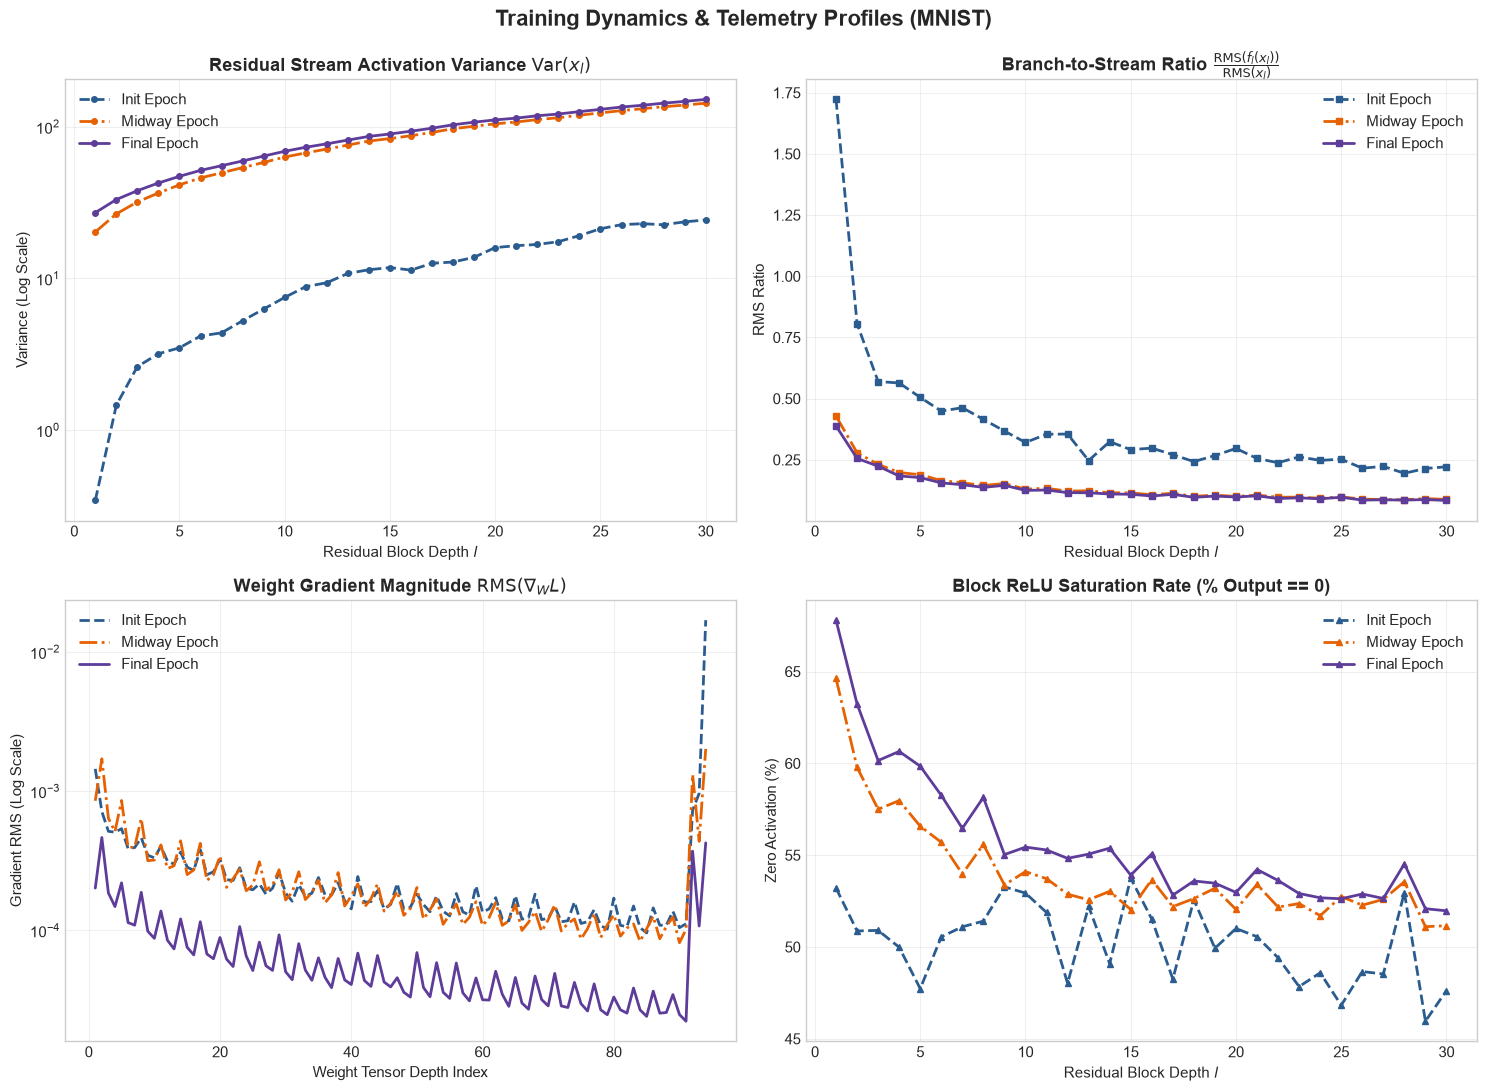

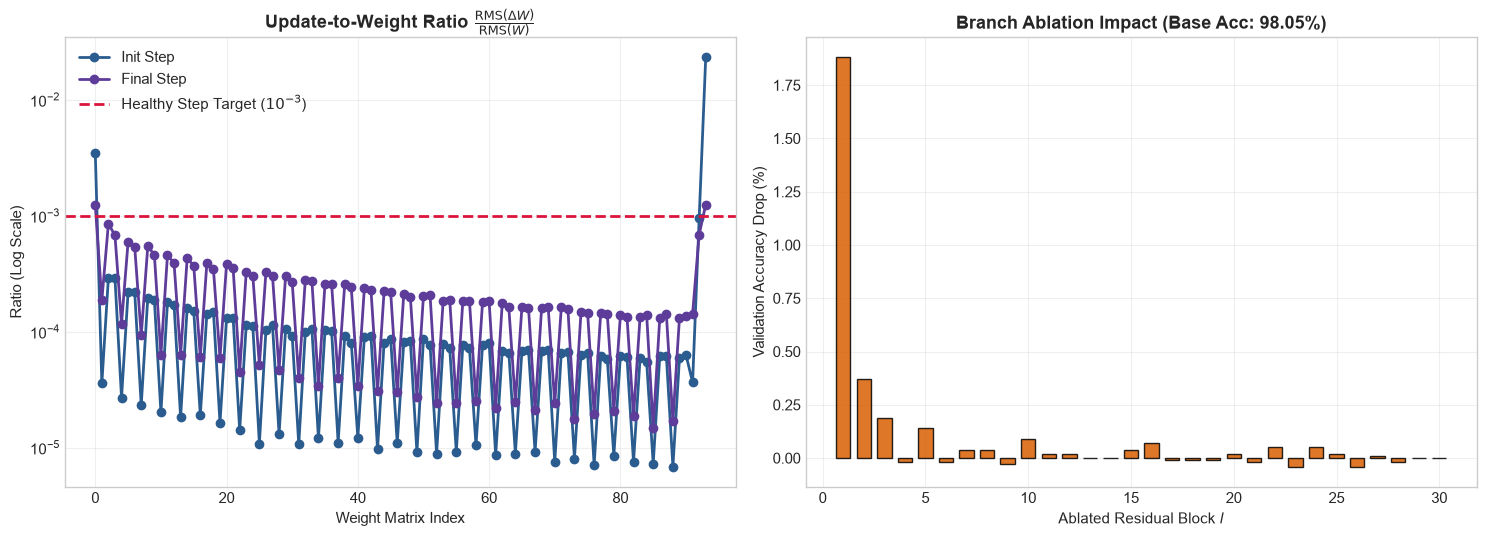

In [18]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

# Render 2x2 Telemetry Matrix
plot_internal_dynamics(snapshots, TASK)

# Render Step Ratio & Branch Sensitivity
plot_update_ratios_and_ablation(snapshots, acc_drops, base_acc)